# EO-3U CubeSat: Electrical Power Analysis

**Model:** [`cubesat.sysml`](cubesat.sysml) · **Orbit:** 500 km SSO · **Scope:** 24 h nominal operations

## 1. Purpose

Verify the electrical power system against the depth-of-discharge and imaging requirements;
assess the deployable solar panels; establish daily imaging capacity.

## 2. Requirements

| ID | Requirement | Rationale |
|---|---|---|
| EPS-1 | Battery state of charge ≥ 70 % in nominal operations | Cell cycle life over a 3-year mission (~16 000 cycles) |
| MIS-1 | ≥ 8 targets imaged per day | Mission imaging plan |

In [1]:
import sysmantic
import pandas as pd
import matplotlib.pyplot as plt

## 3. Configuration

3U bus; two deployable 3U panels (±y) and one body panel (+x), cells facing +x; imager at nadir
(−z); UHF antenna on +z; S-band patch on −z.

*Figure 1. Configuration.*

In [2]:
%viz --view=geometry EarthObserver::CubeSat --height=460

*Figure 2. Power distribution and CAN data bus.*

In [3]:
%viz --view=interconnection EarthObserver::CubeSat --height=520

## 4. Power budget

*Table 1. Load by subsystem and operating mode.*

In [4]:
%viz --view=grid EarthObserver::Loads --height=330 --style=".col-Documentation { display: none; }"

*Table 2. Total load by mode (model roll-up).*

In [5]:
MODES = ["safe", "idle", "imaging", "downlink"]
load = {m: float(sysmantic.evaluate(f"EarthObserver::satellite.{m}Load", unit="W")) for m in MODES}
sysmantic.table(pd.DataFrame({"mode": MODES, "load (W)": [load[m] for m in MODES]}), {"load (W)": "{:.1f}"})

mode,load (W)
safe,1.2
idle,2.2
imaging,10.0
downlink,14.1


## 5. Operating modes

| Transition | Trigger | Guard |
|---|---|---|
| safe → idle | SoC > 60 % | |
| idle → imaging | target in view | SoC > 50 % |
| imaging → idle | after 8 min | |
| idle → downlink | station in view | |
| downlink → idle | pass complete | |
| idle, imaging → safe | SoC < 30 % | |

*Figure 3. Operating modes.*

In [6]:
%viz --view=state-transition EarthObserver::OperatingModes --height=520

*Figure 4. Downlink pass procedure.*

In [7]:
%viz --view=action-flow EarthObserver::DownlinkPass --height=460

*Figure 5. Ground pass: message sequence.*

In [8]:
%viz --view=sequence EarthObserver::GroundPass --height=440

## 6. Analysis: 24 h energy balance

**Method:** time-step simulation at 1 min over 48 h (first 24 h discarded as initialization); mode
logic per §5; panel output and battery capacity from the model.

| Assumption | Value |
|---|---|
| Orbit period / eclipse | 94.6 min / 35.4 min |
| Sun incidence on panels | idle 1.00, downlink 0.55, imaging 0.35, safe 0.30 |
| MPPT efficiency | 0.90 |
| Charge efficiency | 0.92 |
| Ground passes | 4 per day, 9 min each (09:40, 11:20, 21:30, 23:10) |
| Imaging opportunities | daylight only, evenly spaced |

In [9]:
PERIOD, ECLIPSE = 94.6, 35.4          # minutes
ATTITUDE = {"safe": 0.30, "idle": 1.00, "imaging": 0.35, "downlink": 0.55}   # sun on the panels, by mode
MPPT, CHARGING = 0.90, 0.92
PASSES = [(9 * 60 + 40, 9), (11 * 60 + 20, 9), (21 * 60 + 30, 9), (23 * 60 + 10, 9)]   # (start, minutes), each day

def sunlit(t):
    return (t % PERIOD) < PERIOD - ECLIPSE

def simulate(targets_per_day, panel_power, capacity_wh, minutes=2 * 1440):
    """The battery's state of charge and the mode, minute by minute; the targets imaged on the second day."""
    sunlit_minutes = [t for t in range(1440) if sunlit(t)]
    step = len(sunlit_minutes) / targets_per_day if targets_per_day else None
    target_times = {sunlit_minutes[int(i * step)] for i in range(targets_per_day)} if step else set()
    soc, mode, timer, imaged, rows = 0.95, "safe", 0, 0, []
    for t in range(minutes):
        day_t = t % 1440
        in_pass = any(s <= day_t < s + d for s, d in PASSES)
        # The state machine's transitions, with its guards.
        if mode == "safe" and soc > 0.6:
            mode = "idle"
        elif mode == "idle" and soc < 0.3:
            mode = "safe"
        elif mode == "idle" and in_pass:
            mode = "downlink"
        elif mode == "idle" and day_t in target_times and soc > 0.5:
            mode, timer = "imaging", 8
            imaged += t >= 1440
        elif mode == "imaging" and soc < 0.3:
            mode = "safe"
        elif mode == "imaging":
            timer -= 1
            mode = "idle" if timer <= 0 else mode
        elif mode == "downlink" and not in_pass:
            mode = "idle"
        generated = panel_power * ATTITUDE[mode] * MPPT if sunlit(t) else 0.0
        net = generated - load[mode]
        soc = min(1.0, max(0.0, soc + (net * (CHARGING if net > 0 else 1.0)) / 60 / capacity_wh))
        rows.append((t, soc, mode, sunlit(t)))
    run = pd.DataFrame(rows, columns=["minute", "charge", "mode", "sunlit"])
    return run, imaged

panels = {p: float(sysmantic.evaluate(f"EarthObserver::satellite.{p}.peakPower", unit="W")) for p in ("leftPanel", "rightPanel", "bodyPanel")}
capacity = float(sysmantic.evaluate("EarthObserver::satellite.battery.capacity", unit="W*h"))
print(panels, f"battery {capacity:g} Wh")

{'leftPanel': 7.6, 'rightPanel': 7.6, 'bodyPanel': 2.4} battery 50 Wh


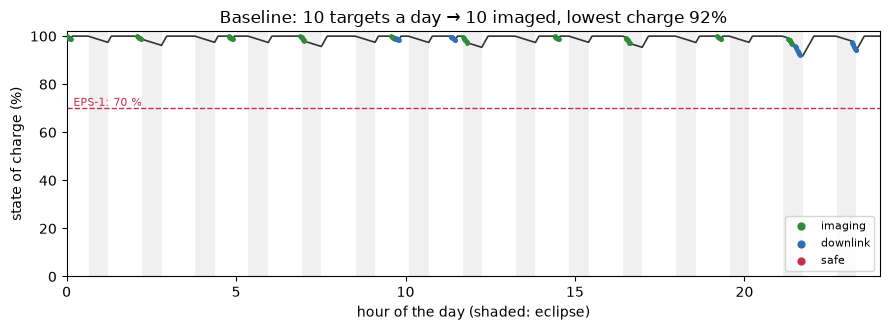

In [10]:
COLORS = {"safe": "#c4314b", "idle": "#9da7b3", "imaging": "#2f8a3a", "downlink": "#2f6fb5"}

def plot(run, title):
    day = run[run.minute >= 1440].assign(hour=lambda r: (r.minute - 1440) / 60)
    fig, ax = plt.subplots(figsize=(9, 3.4))
    for _, g in day[~day.sunlit].groupby((day.sunlit != day.sunlit.shift()).cumsum()):
        ax.axvspan(g.hour.iloc[0], g.hour.iloc[-1], color="#000", alpha=0.06, lw=0)
    ax.plot(day.hour, day.charge * 100, color="#333", lw=1.2)
    for mode in ("imaging", "downlink", "safe"):
        sel = day[day["mode"] == mode]
        ax.scatter(sel.hour, sel.charge * 100, s=6, color=COLORS[mode], label=mode, zorder=3)
    ax.axhline(70, color="#c4314b", ls="--", lw=1)
    ax.text(0.2, 71, "EPS-1: 70 %", color="#c4314b", fontsize=8)
    ax.set_xlim(0, 24); ax.set_ylim(0, 102); ax.set_xlabel("hour of the day (shaded: eclipse)"); ax.set_ylabel("state of charge (%)")
    ax.set_title(title); ax.legend(loc="lower right", fontsize=8, markerscale=2); plt.tight_layout()

run, imaged = simulate(10, sum(panels.values()), capacity)
lowest = run[run.minute >= 1440].charge.min()
plot(run, f"Baseline: 10 targets a day → {imaged} imaged, lowest charge {lowest:.0%}")

*Figure 6. Baseline (10 targets/day): state of charge over 24 h.*

Results recorded in the model; requirements verified:

In [11]:
def assess(name, panel_power, targets, left_right=True):
    run, imaged = simulate(targets, panel_power, capacity)
    lowest = run[run.minute >= 1440].charge.min()
    stowed = "" if left_right else "part :>> leftPanel { attribute :>> peakPower = 0 [W]; attribute :>> mass = 0 [kg]; } part :>> rightPanel { attribute :>> peakPower = 0 [W]; attribute :>> mass = 0 [kg]; }"
    sysmantic.sysml(f"""package {name} {{
	private import EarthObserver::*;
	private import Requirements::*;
	private import SI::*;
	part design :> satellite {{
		{stowed}
		attribute :>> lowestCharge = {lowest:.3f};
		attribute :>> imagesPerDay = {imaged};
	}}
	requirement charge : DepthOfDischarge {{ subject :>> s = design; }}
	requirement imaging : ImagingCapacity {{ subject :>> s = design; }}
}}""", name)
    return run, {"design": name, "targets planned": targets, "imaged": imaged, "lowest charge": round(lowest, 3),
                 "EPS-1": sysmantic.verify(f"{name}::charge").verdict, "MIS-1": sysmantic.verify(f"{name}::imaging").verdict}

_, baseline = assess("EpsBaseline", sum(panels.values()), 10)
sysmantic.table(pd.DataFrame([baseline]), {"lowest charge": "{:.1%}"})

design,targets planned,imaged,lowest charge,EPS-1,MIS-1
EpsBaseline,10,10,91.7%,satisfied,satisfied


## 7. Option: body-mounted cells only

Deleting the deployable panels removes the hinge and release mechanism, their cost, and a
single-point deployment risk. Body panel only: 2.4 W peak.

design,targets planned,imaged,lowest charge,EPS-1,MIS-1
EpsBaseline,10,10,91.7%,satisfied,satisfied
EpsBodyOnly,10,0,0.0%,violated,violated


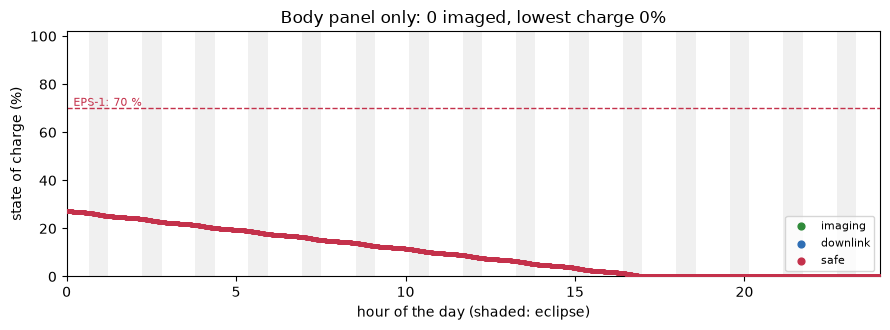

In [12]:
body_only, body = assess("EpsBodyOnly", panels["bodyPanel"], 10, left_right=False)
plot(body_only, f"Body panel only: {body['imaged']} imaged, lowest charge {body['lowest charge']:.0%}")
sysmantic.table(pd.DataFrame([baseline, body]), {"lowest charge": "{:.1%}"})

**Finding:** negative energy balance in every mode, including safe mode. Battery depleted; the
imaging guard (SoC > 50 %) is never met. EPS-1 and MIS-1 violated.

**Decision:** deployable panels retained.

## 8. Imaging capacity: power

Targets per day swept from 8 to 104 with the deployable panels; capacity is the largest plan that
holds EPS-1.

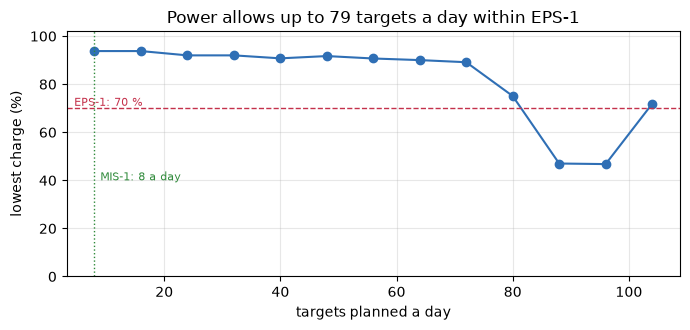

In [13]:
sweep = []
for targets in range(8, 105, 8):
    run, imaged = simulate(targets, sum(panels.values()), capacity)
    sweep.append({"targets planned": targets, "imaged": imaged, "lowest charge": run[run.minute >= 1440].charge.min()})
sweep = pd.DataFrame(sweep)
capacity_limit = sweep[sweep["lowest charge"] >= 0.70]["imaged"].max()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(sweep["targets planned"], sweep["lowest charge"] * 100, marker="o", color="#2f6fb5")
ax.axhline(70, color="#c4314b", ls="--", lw=1); ax.text(4.5, 71, "EPS-1: 70 %", color="#c4314b", fontsize=8)
ax.axvline(8, color="#2f8a3a", ls=":", lw=1); ax.text(9, 40, "MIS-1: 8 a day", color="#2f8a3a", fontsize=8)
ax.set_xlabel("targets planned a day"); ax.set_ylabel("lowest charge (%)"); ax.set_ylim(0, 102); ax.grid(alpha=.3)
ax.set_title(f"Power allows up to {capacity_limit} targets a day within EPS-1"); plt.tight_layout()

**Finding:** power supports 79 scenes per day within EPS-1, well above MIS-1. Above about 80
planned, the imaging guard (SoC > 50 %) starts refusing targets: fewer are imaged, and the
lowest charge recovers. Capacity is counted in scenes imaged, not planned.

## 9. Imaging capacity: downlink

| Assumption | Value |
|---|---|
| Scene | 20 × 20 km at 5 m GSD: 4000 × 4000 px, 4 bands, 12 bit |
| Compression | 3:1 (32 MB per scene) |
| Contact time | 4 passes × 9 min per day |
| S-band rate | from the model |

In [14]:
rate = float(sysmantic.evaluate("EarthObserver::satellite.sBand.dataRate", unit="Hz"))   # bit/s
per_day_mb = rate * sum(d for _, d in PASSES) * 60 / 8 / 1e6
scene_mb = 4000 * 4000 * 4 * 12 / 8 / 1e6 / 3
downlink_limit = int(per_day_mb // scene_mb)
sysmantic.table(pd.DataFrame([{"S-band rate (Mbit/s)": rate / 1e6, "downlinked a day (MB)": round(per_day_mb), "scene (MB)": round(scene_mb),
               "scenes a day, by downlink": downlink_limit, "scenes a day, by power": capacity_limit}]), {"S-band rate (Mbit/s)": "{:.1f}"})

S-band rate (Mbit/s),downlinked a day (MB),scene (MB),"scenes a day, by downlink","scenes a day, by power"
2.0,540,32,16,79


**Finding:** downlink limits capacity to 16 scenes per day. MIS-1 is met with margin (2×).

**Recommendation:** for growth beyond 16 scenes per day, add ground contacts or increase S-band
rate; battery and array are not the constraint.

## 10. Result

Selected configuration at its downlink-limited capacity, recorded in the model:

In [15]:
run, recorded = assess("EpsSelected", sum(panels.values()), min(capacity_limit, downlink_limit))
sysmantic.table(pd.DataFrame([recorded]), {"lowest charge": "{:.1%}"})

design,targets planned,imaged,lowest charge,EPS-1,MIS-1
EpsSelected,16,16,93.8%,satisfied,satisfied


## 11. Operational constraints

Imaging is inhibited below 50 % SoC; transition to safe mode below 30 %.

*Figure 7. Operating modes, constraint states highlighted.*

In [16]:
%viz --view=state-transition EarthObserver::OperatingModes --highlight=EarthObserver::OperatingModes::imaging,EarthObserver::OperatingModes::safe --height=520